
# Book Recommender System using Medallion Data Lake

**Data Mining Lab Assignment**

This project implements a Bronze-Silver-Gold data lake pipeline using the Book-Crossing dataset and builds an item-based collaborative filtering recommender system using cosine similarity.

### Technologies Used
- Python
- Pandas
- NumPy
- SciPy
- Scikit-learn
- Matplotlib and Seaborn



In [1]:

!pip install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn


In [2]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime, timezone
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

folders = ["bronze", "silver", "gold"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Data Lake folders created successfully!")

for folder in folders:
    print(f"{folder}/")


Data Lake folders created successfully!
bronze/
silver/
gold/


In [3]:

import requests
import zipfile

dataset_url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

response = requests.get(dataset_url)
response.raise_for_status()

with open("book-crossings.zip", "wb") as file:
    file.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("raw_data")

print("Dataset downloaded and extracted successfully!")

print(os.listdir("raw_data"))


Dataset downloaded and extracted successfully!
['BX-Books.csv', 'BX-Book-Ratings.csv', 'BX-Users.csv']


In [5]:

users_raw = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

books_raw = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn",
    engine="python"
)

ratings_raw = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

print("Datasets loaded!")
print("Users:", users_raw.shape)
print("Books:", books_raw.shape)
print("Ratings:", ratings_raw.shape)


/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 815: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 1679: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 2531: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 2640: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 3236: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 3256: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 4906: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/1809311244.py:8: ParserWarning: Skipping line 6452: ';' expected after '"'

  books_raw = pd.read_csv(
/tmp/ipykernel_588/180931

Datasets loaded!
Users: (278858, 3)
Books: (270491, 8)
Ratings: (1149780, 3)


In [6]:
ingestion_time = datetime.now(timezone.utc)

users_bronze = users_raw.copy()
books_bronze = books_raw.copy()
ratings_bronze = ratings_raw.copy()

users_bronze["ingestion_timestamp"] = ingestion_time
books_bronze["ingestion_timestamp"] = ingestion_time
ratings_bronze["ingestion_timestamp"] = ingestion_time

users_bronze.to_parquet("bronze/users.parquet", index=False)
books_bronze.to_parquet("bronze/books.parquet", index=False)
ratings_bronze.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer created successfully!")
print(os.listdir("bronze"))


Bronze layer created successfully!
['ratings.parquet', 'users.parquet', 'books.parquet']


In [7]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded successfully!")

print("\nUsers:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)


Bronze datasets loaded successfully!

Users: (278858, 4)
Books: (270491, 9)
Ratings: (1149780, 4)


In [8]:
datasets = {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"{name.upper()} DATASET")
    print(f"{'='*50}")

    print("\nShape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())



USERS DATASET

Shape: (278858, 4)

Data Types:
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

BOOKS DATASET

Shape: (270491, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0


Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of zero ratings: 716109
Number of explicit ratings: 433671


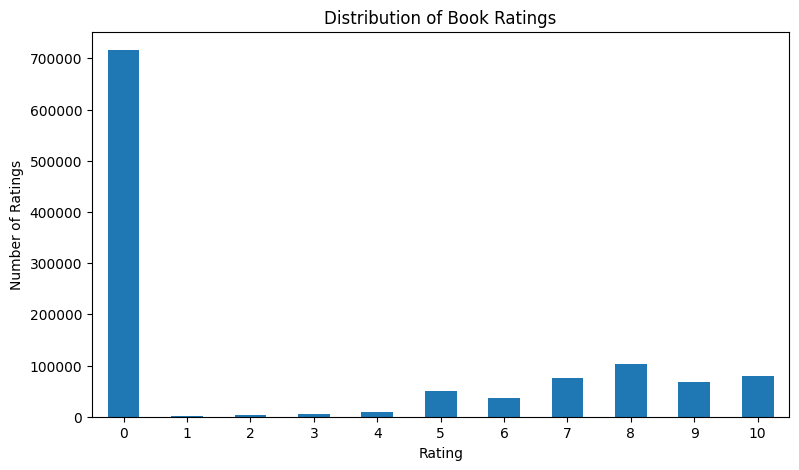

In [9]:

rating_counts = ratings["Book-Rating"].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

print("\nNumber of zero ratings:",
      (ratings["Book-Rating"] == 0).sum())

print("Number of explicit ratings:",
      ((ratings["Book-Rating"] >= 1) &
       (ratings["Book-Rating"] <= 10)).sum())

plt.figure(figsize=(9, 5))
rating_counts.plot(kind="bar")

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()


Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing ages: 110762
Ages below 5: 882
Ages above 100: 366


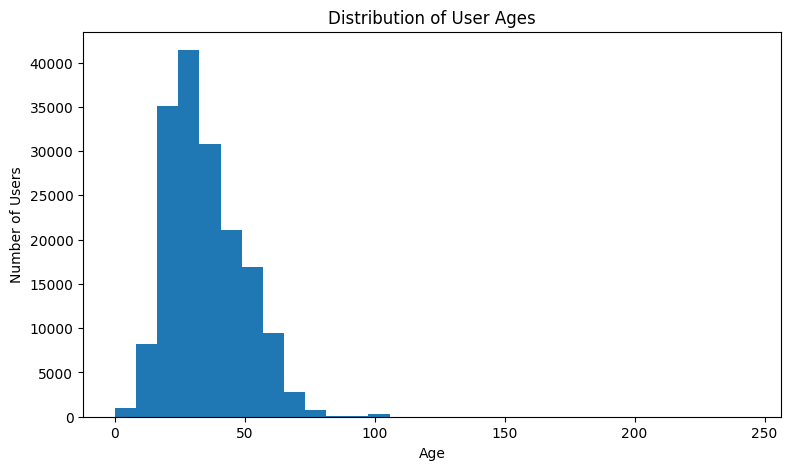

In [10]:

print("Age Statistics:")
print(users["Age"].describe())

print("\nMissing ages:", users["Age"].isnull().sum())
print("Ages below 5:", (users["Age"] < 5).sum())
print("Ages above 100:", (users["Age"] > 100).sum())

plt.figure(figsize=(9, 5))
users["Age"].dropna().plot(kind="hist", bins=30)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()


Publication Year Statistics:
count    270491.000000
mean       1959.704914
std         258.207234
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Year equal to zero: 4611
Future publication years: 11


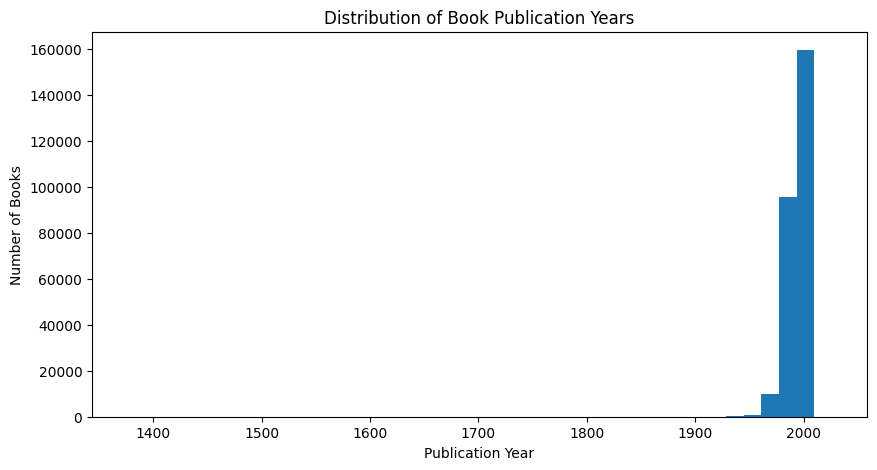

In [11]:

books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

print("Publication Year Statistics:")
print(books["Year-Of-Publication"].describe())

current_year = datetime.now().year

print("\nYear equal to zero:",
      (books["Year-Of-Publication"] == 0).sum())

print("Future publication years:",
      (books["Year-Of-Publication"] > current_year).sum())

valid_years = books[
    (books["Year-Of-Publication"] > 0) &
    (books["Year-Of-Publication"] <= current_year)
]

plt.figure(figsize=(10, 5))
valid_years["Year-Of-Publication"].plot(kind="hist", bins=40)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.show()


Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


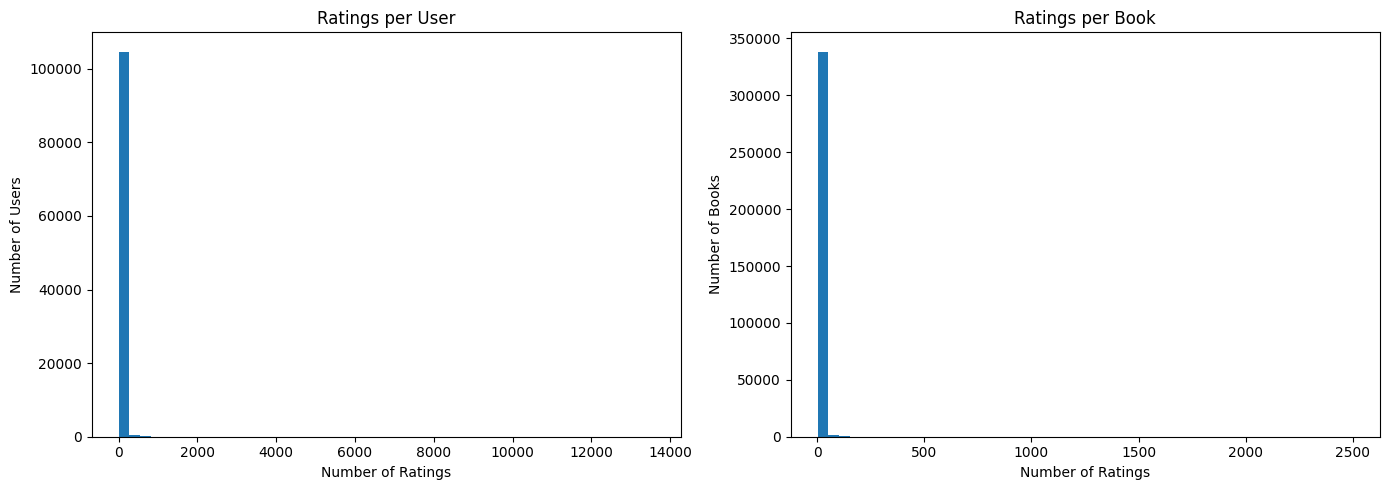

In [12]:

ratings_per_user = ratings.groupby("User-ID").size()

ratings_per_book = ratings.groupby("ISBN").size()

print("Ratings per User:")
print(ratings_per_user.describe())

print("\nRatings per Book:")
print(ratings_per_book.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ratings_per_user, bins=50)
axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Number of Users")

axes[1].hist(ratings_per_book, bins=50)
axes[1].set_title("Ratings per Book")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Number of Books")

plt.tight_layout()
plt.show()


In [13]:



total_users = ratings["User-ID"].nunique()
total_books = ratings["ISBN"].nunique()

rated_pairs = ratings[["User-ID", "ISBN"]].drop_duplicates().shape[0]

total_possible_pairs = total_users * total_books

sparsity = (
    1 - rated_pairs / total_possible_pairs
) * 100

print("Unique Users:", total_users)
print("Unique Books:", total_books)
print("Distinct Rated User-Book Pairs:", rated_pairs)
print("Total Possible User-Book Pairs:", total_possible_pairs)

print(f"\nMatrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100-sparsity:.4f}%")


Unique Users: 105283
Unique Books: 340556
Distinct Rated User-Book Pairs: 1149780
Total Possible User-Book Pairs: 35854757348

Matrix Sparsity: 99.9968%
Matrix Density: 0.0032%



## EDA Observations and Planned Silver Transformations

1. **Dataset structure and missing values:** The Users dataset contains 278,858 records, Books contains 270,491 records, and Ratings contains 1,149,780 records. The Users dataset has 110,762 missing ages, while Books has 2 missing authors and 2 missing publishers. Missing ages will be imputed using the median, and missing book metadata will be handled appropriately.

2. **Rating distribution:** Out of 1,149,780 ratings, 716,109 (approximately 62.28%) are zero, representing implicit feedback rather than explicit ratings. These will be removed, retaining only ratings from 1 to 10.

3. **User age distribution:** The median age is 32 years, with a minimum of 0 and a maximum of 244. There are 882 users below age 5 and 366 above age 100. These invalid ages will be set to null, and missing values will be filled with the median age.

4. **Publication year distribution:** Publication years range from 0 to 2050, with a median of 1995. There are 4,611 books with publication year 0 and 11 with future publication years. These invalid years will be replaced with null.

5. **Ratings per user and book:** The median number of ratings per user is 1, while the median number of ratings per book is also 1. Most users and books have very few ratings, indicating a highly uneven distribution. A minimum rating threshold of 10 will be applied to retain users and books with sufficient rating activity.

6. **Matrix sparsity:** The user-book matrix has 105,283 unique users and 340,556 unique books, with 1,149,780 rated pairs. Its sparsity is approximately 99.9968%, indicating that only 0.0032% of possible user-book combinations have ratings. Therefore, a sparse matrix representation will be used in the Gold layer.


In [14]:

users_silver = pd.read_parquet("bronze/users.parquet")
books_silver = pd.read_parquet("bronze/books.parquet")
ratings_silver = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded for Silver processing.")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Bronze datasets loaded for Silver processing.
Users: (278858, 4)
Books: (270491, 9)
Ratings: (1149780, 4)


In [15]:

print("Duplicates before cleaning:")

print("Users:", users_silver.duplicated(subset=["User-ID"]).sum())
print("Books:", books_silver.duplicated(subset=["ISBN"]).sum())
print("Ratings:", ratings_silver.duplicated().sum())

users_silver = users_silver.drop_duplicates(subset=["User-ID"], keep="first")
books_silver = books_silver.drop_duplicates(subset=["ISBN"], keep="first")
ratings_silver = ratings_silver.drop_duplicates()

print("\nDuplicates removed.")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Duplicates before cleaning:
Users: 0
Books: 0
Ratings: 0

Duplicates removed.
Users: (278858, 4)
Books: (270491, 9)
Ratings: (1149780, 4)


In [16]:

ratings_silver = ratings_silver[
    ratings_silver["Book-Rating"].between(1, 10)
].copy()

print("Ratings after removing zero and invalid ratings:", ratings_silver.shape)

print("\nRating distribution after cleaning:")
print(ratings_silver["Book-Rating"].value_counts().sort_index())


Ratings after removing zero and invalid ratings: (433671, 4)

Rating distribution after cleaning:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


In [17]:

users_silver["Age"] = pd.to_numeric(users_silver["Age"], errors="coerce")

users_silver.loc[
    (users_silver["Age"] < 5) | (users_silver["Age"] > 100),
    "Age"
] = np.nan

median_age = users_silver["Age"].median()

users_silver["Age"] = users_silver["Age"].fillna(median_age)

print("Median age used:", median_age)
print("Missing ages after cleaning:", users_silver["Age"].isnull().sum())

print("\nAge statistics after cleaning:")
print(users_silver["Age"].describe())


Median age used: 32.0
Missing ages after cleaning: 0

Age statistics after cleaning:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [18]:

location_parts = (
    users_silver["Location"]
    .fillna("")
    .astype(str)
    .str.split(",", n=2, expand=True)
)

for i in range(3):
    if i not in location_parts.columns:
        location_parts[i] = np.nan

users_silver["City"] = location_parts[0].fillna("").str.strip().str.title()
users_silver["State"] = location_parts[1].fillna("").str.strip().str.title()
users_silver["Country"] = location_parts[2].fillna("").str.strip().str.title()

users_silver = users_silver.drop(columns=["Location"])

print(users_silver[["City", "State", "Country"]].head())


          City            State         Country
0          Nyc         New York             Usa
1     Stockton       California             Usa
2       Moscow  Yukon Territory          Russia
3        Porto         V.N.Gaia        Portugal
4  Farnborough            Hants  United Kingdom


In [19]:

books_silver["Year-Of-Publication"] = pd.to_numeric(
    books_silver["Year-Of-Publication"],
    errors="coerce"
)

current_year = datetime.now().year

books_silver.loc[
    (books_silver["Year-Of-Publication"] == 0) |
    (books_silver["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

books_silver["Year-Of-Publication"] = (
    books_silver["Year-Of-Publication"].astype("Int64")
)

print("Invalid publication years remaining:",
      ((books_silver["Year-Of-Publication"] == 0) |
       (books_silver["Year-Of-Publication"] > current_year)).sum())

print("\nMissing publication years:",
      books_silver["Year-Of-Publication"].isnull().sum())


Invalid publication years remaining: 0

Missing publication years: 4622


In [20]:

text_columns = ["Book-Title", "Book-Author", "Publisher"]

for col in text_columns:
    books_silver[col] = (
        books_silver[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

books_silver["ISBN"] = books_silver["ISBN"].astype(str).str.strip()

books_silver = books_silver.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"]
)

for col in ["City", "State", "Country"]:
    users_silver[col] = (
        users_silver[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

print("Text cleaning completed.")
print("\nBook columns:")
print(books_silver.columns.tolist())

print("\nUser columns:")
print(users_silver.columns.tolist())


Text cleaning completed.

Book columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']

User columns:
['User-ID', 'Age', 'ingestion_timestamp', 'City', 'State', 'Country']


In [21]:

valid_user_ids = set(users_silver["User-ID"])
valid_book_ids = set(books_silver["ISBN"])

ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(valid_user_ids) &
    ratings_silver["ISBN"].isin(valid_book_ids)
].copy()

print("Ratings after validating user and book IDs:", ratings_silver.shape)


Ratings after validating user and book IDs: (382827, 4)


In [22]:

min_ratings = 10

previous_shape = None

while previous_shape != ratings_silver.shape:
    previous_shape = ratings_silver.shape

    user_counts = ratings_silver["User-ID"].value_counts()
    book_counts = ratings_silver["ISBN"].value_counts()

    valid_users = user_counts[user_counts >= min_ratings].index
    valid_books = book_counts[book_counts >= min_ratings].index

    ratings_silver = ratings_silver[
        ratings_silver["User-ID"].isin(valid_users) &
        ratings_silver["ISBN"].isin(valid_books)
    ].copy()

print("Threshold filtering completed.")

print("Remaining ratings:", ratings_silver.shape[0])
print("Remaining users:", ratings_silver["User-ID"].nunique())
print("Remaining books:", ratings_silver["ISBN"].nunique())


Threshold filtering completed.
Remaining ratings: 41238
Remaining users: 1813
Remaining books: 2022


In [23]:

retained_users = ratings_silver["User-ID"].unique()
retained_books = ratings_silver["ISBN"].unique()

users_silver = users_silver[
    users_silver["User-ID"].isin(retained_users)
].copy()

books_silver = books_silver[
    books_silver["ISBN"].isin(retained_books)
].copy()

print("Final Silver dataset shapes:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Final Silver dataset shapes:
Users: (1813, 6)
Books: (2022, 6)
Ratings: (41238, 4)


In [24]:

user_rating_counts = ratings_silver.groupby("User-ID").size()
book_rating_counts = ratings_silver.groupby("ISBN").size()

print("Minimum ratings by a user:", user_rating_counts.min())
print("Minimum ratings for a book:", book_rating_counts.min())

print("Users below threshold:", (user_rating_counts < min_ratings).sum())
print("Books below threshold:", (book_rating_counts < min_ratings).sum())


Minimum ratings by a user: 10
Minimum ratings for a book: 10
Users below threshold: 0
Books below threshold: 0


In [25]:

os.makedirs("silver", exist_ok=True)

users_silver.to_parquet("silver/users.parquet", index=False)
books_silver.to_parquet("silver/books.parquet", index=False)
ratings_silver.to_parquet("silver/ratings.parquet", index=False)

users_silver.to_csv("silver/users.csv", index=False)
books_silver.to_csv("silver/books.csv", index=False)
ratings_silver.to_csv("silver/ratings.csv", index=False)

print("Silver layer saved successfully!")
print(os.listdir("silver"))


Silver layer saved successfully!
['ratings.parquet', 'users.parquet', 'users.csv', 'ratings.csv', 'books.csv', 'books.parquet']


In [26]:

print("FINAL SILVER LAYER SUMMARY")

print("\nUsers:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

print("\nMissing values:")

for name, df in {
    "Users": users_silver,
    "Books": books_silver,
    "Ratings": ratings_silver
}.items():
    print(f"\n{name}:")
    print(df.isnull().sum())

print("\nRating distribution:")
print(ratings_silver["Book-Rating"].value_counts().sort_index())


FINAL SILVER LAYER SUMMARY

Users: (1813, 6)
Books: (2022, 6)
Ratings: (41238, 4)

Missing values:

Users:
User-ID                0
Age                    0
ingestion_timestamp    0
City                   0
State                  0
Country                0
dtype: int64

Books:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    4
Publisher              0
ingestion_timestamp    0
dtype: int64

Ratings:
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64

Rating distribution:
Book-Rating
1       121
2       181
3       362
4       578
5      3472
6      2757
7      6404
8     10126
9      7967
10     9270
Name: count, dtype: int64



## Silver Layer - Preprocessing Summary

The following preprocessing operations were performed:

1. Removed duplicate users, books and rating records.
2. Removed zero ratings and retained explicit ratings between 1 and 10.
3. Replaced invalid user ages with null and filled missing ages using the median.
4. Split user locations into city, state and country.
5. Replaced zero and future publication years with null.
6. Cleaned text columns by removing extra spaces and standardizing capitalization.
7. Replaced missing author and publisher values with "Unknown".
8. Removed unnecessary image URL columns from the Books dataset.
9. Removed ratings associated with users or books not present in the corresponding tables.
10. Applied an iterative minimum threshold of 10 ratings per user and per book.

The cleaned Users, Books and Ratings datasets were saved in the Silver layer in Parquet and CSV formats.


In [27]:

os.makedirs("gold", exist_ok=True)

users_silver = pd.read_parquet("silver/users.parquet")
books_silver = pd.read_parquet("silver/books.parquet")
ratings_silver = pd.read_parquet("silver/ratings.parquet")

print("Silver datasets loaded successfully.")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)


Silver datasets loaded successfully.
Users: (1813, 6)
Books: (2022, 6)
Ratings: (41238, 4)


In [28]:

user_ids = ratings_silver["User-ID"].unique()
book_isbns = ratings_silver["ISBN"].unique()

user_to_index = {user_id: idx for idx, user_id in enumerate(user_ids)}
book_to_index = {isbn: idx for idx, isbn in enumerate(book_isbns)}

row_indices = ratings_silver["User-ID"].map(user_to_index).values
col_indices = ratings_silver["ISBN"].map(book_to_index).values
rating_values = ratings_silver["Book-Rating"].values

rating_matrix = csr_matrix(
    (rating_values, (row_indices, col_indices)),
    shape=(len(user_ids), len(book_isbns))
)

print("Sparse rating matrix created successfully!")
print("Matrix shape:", rating_matrix.shape)
print("Number of stored ratings:", rating_matrix.nnz)
print("Matrix density:", rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]) * 100, "%")



Sparse rating matrix created successfully!
Matrix shape: (1813, 2022)
Number of stored ratings: 41238
Matrix density: 1.1249122313132487 %


In [29]:

save_npz("gold/user_book_matrix.npz", rating_matrix)

user_mapping = pd.DataFrame({
    "matrix_index": range(len(user_ids)),
    "User-ID": user_ids
})

book_mapping = pd.DataFrame({
    "matrix_index": range(len(book_isbns)),
    "ISBN": book_isbns
})

user_mapping.to_csv("gold/user_mapping.csv", index=False)
book_mapping.to_csv("gold/book_mapping.csv", index=False)

print("Sparse matrix and index mappings saved successfully.")


Sparse matrix and index mappings saved successfully.


In [30]:

book_lookup = books_silver[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()

book_lookup.to_csv("gold/book_lookup.csv", index=False)

print("Book lookup table created.")
print(book_lookup.head(10))


Book lookup table created.
         ISBN                            Book-Title         Book-Author
0  0440234743                         The Testament        John Grisham
1  0452264464  Beloved (Plume Contemporary Fiction)       Toni Morrison
2  0971880107                           Wild Animus        Rich Shapero
3  0345402871                              Airframe    Michael Crichton
4  0345417623                              Timeline    Michael Crichton
5  0446310786                 To Kill A Mockingbird          Harper Lee
6  0449005615        Seabiscuit: An American Legend   Laura Hillenbrand
7  0671888587                    I'Ll Be Seeing You  Mary Higgins Clark
8  0553582747            From The Corner Of His Eye         Dean Koontz
9  0425182908                          Isle Of Dogs   Patricia Cornwell


In [31]:

user_aggregates = ratings_silver.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

user_aggregates.to_csv("gold/user_aggregates.csv", index=False)

print("User-level aggregates:")
print(user_aggregates.head(10))


User-level aggregates:
   User-ID  average_rating  number_of_ratings
0      243        7.769231                 13
1      254        8.450000                 20
2      638        9.454545                 22
3      805        8.400000                 10
4      882        8.235294                 17
5     1131        6.857143                 14
6     1424        7.181818                 11
7     1435        6.615385                 13
8     1733        7.181818                 11
9     1848        8.600000                 10


In [32]:

book_aggregates = ratings_silver.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates.to_csv("gold/book_aggregates.csv", index=False)

print("Book-level aggregates:")
print(book_aggregates.head(10))


Book-level aggregates:
         ISBN  average_rating  number_of_ratings
0  0020199600        8.090909                 11
1  0020442203        8.833333                 12
2  002542730X        7.481481                 27
3  0028604199        7.900000                 10
4  0060002050        7.545455                 11
5  006000438X        7.277778                 18
6  0060008032        7.388889                 18
7  006001203X        8.090909                 11
8  0060085444        7.083333                 12
9  0060085452        8.111111                 18


In [33]:

loaded_matrix = load_npz("gold/user_book_matrix.npz")

print("GOLD LAYER VERIFICATION")

print("\nSparse Matrix Shape:", loaded_matrix.shape)
print("Stored Ratings:", loaded_matrix.nnz)

print("\nUser Mapping:", user_mapping.shape)
print("Book Mapping:", book_mapping.shape)
print("Book Lookup:", book_lookup.shape)
print("User Aggregates:", user_aggregates.shape)
print("Book Aggregates:", book_aggregates.shape)

print("\nGold Layer Files:")
print(os.listdir("gold"))

print("\nAll Gold layer components created successfully!")


GOLD LAYER VERIFICATION

Sparse Matrix Shape: (1813, 2022)
Stored Ratings: 41238

User Mapping: (1813, 2)
Book Mapping: (2022, 2)
Book Lookup: (2022, 3)
User Aggregates: (1813, 3)
Book Aggregates: (2022, 3)

Gold Layer Files:
['book_lookup.csv', 'user_book_matrix.npz', 'user_mapping.csv', 'book_aggregates.csv', 'user_aggregates.csv', 'book_mapping.csv']

All Gold layer components created successfully!



## Gold Layer - Model Ready Data

The Gold layer was created using the cleaned Silver datasets.

The following components were generated:

1. **User-Book Rating Matrix:** Created a sparse CSR matrix with users as rows and books as columns. The matrix stores only non-zero explicit ratings to reduce memory usage.

2. **Index Mappings:** Created separate mappings to associate matrix indices with original User IDs and ISBNs.

3. **Book Lookup Table:** Created a lookup table containing ISBN, book title and author to display readable recommendations.

4. **User Aggregates:** Calculated the average rating and total number of ratings given by each user.

5. **Book Aggregates:** Calculated the average rating and total number of ratings received by each book.

The sparse matrix and supporting lookup and aggregate tables were saved in the Gold directory for use in the recommendation model.


In [34]:
from sklearn.neighbors import NearestNeighbors

book_user_matrix = rating_matrix.T.tocsr()

knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user_matrix)

print("Book-user matrix shape:", book_user_matrix.shape)
print("Item similarity model trained successfully!")

Book-user matrix shape: (2022, 1813)
Item similarity model trained successfully!


In [35]:
book_info = books_silver.set_index("ISBN")[["Book-Title", "Book-Author"]].reindex(book_isbns)

def get_similar_books(book_title, n=10):
    query = str(book_title).strip()

    if query in book_to_index:
        book_idx = book_to_index[query]
    else:
        matches = book_info[
            book_info["Book-Title"].str.casefold() == query.casefold()
        ]

        if matches.empty:
            matches = book_info[
                book_info["Book-Title"].str.contains(query, case=False, na=False)
            ]

        if matches.empty:
            return pd.DataFrame(columns=["Book-Title", "Book-Author", "Similarity"])

        book_idx = book_to_index[matches.index[0]]

    k = min(n + 1, len(book_isbns))
    distances, indices = knn.kneighbors(book_user_matrix[book_idx], n_neighbors=k)

    results = []

    for distance, idx in zip(distances[0], indices[0]):
        if idx == book_idx:
            continue

        results.append({
            "Book-Title": book_info.iloc[idx]["Book-Title"],
            "Book-Author": book_info.iloc[idx]["Book-Author"],
            "Similarity": round(1 - distance, 4)
        })

    return pd.DataFrame(results).head(n)

In [36]:
sample_book = book_info["Book-Title"].iloc[0]

print("Selected book:", sample_book)
display(get_similar_books(sample_book, n=10))

Selected book: Politically Correct Bedtime Stories: Modern Tales For Our Life And Times


,Book-Title,Book-Author,Similarity
0,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,0.2111
1,The Once And Future King,T. H. White,0.2045
2,Don'T Stand Too Close To A Naked Man,Tim Allen,0.1591
3,Stuart Little,E. B. White,0.1521
4,Dracula (Signet Classics (Paperback)),Bram Stoker,0.1512
5,The Lilac Bus: Stories,Maeve Binchy,0.1505
6,Leap Of Faith,Danielle Steel,0.1504
7,To Love Again,Danielle Steel,0.1489
8,Trading Places,Fern Michaels,0.1489
9,The Hundred Secret Senses,Amy Tan,0.1460


In [37]:
def recommend(user_id, n=10):
    if user_id not in user_to_index:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Score"])

    user_idx = user_to_index[user_id]
    user_ratings = rating_matrix.getrow(user_idx)

    rated_books = dict(zip(user_ratings.indices, user_ratings.data))

    preferred_books = [
        (book_idx, rating)
        for book_idx, rating in rated_books.items()
        if rating >= 7
    ]

    if not preferred_books:
        preferred_books = list(rated_books.items())

    candidate_scores = {}

    for book_idx, rating in preferred_books:
        distances, indices = knn.kneighbors(
            book_user_matrix[book_idx],
            n_neighbors=min(21, len(book_isbns))
        )

        for distance, similar_idx in zip(distances[0], indices[0]):
            similarity = 1 - distance

            if similar_idx in rated_books or similar_idx == book_idx:
                continue

            candidate_scores[similar_idx] = (
                candidate_scores.get(similar_idx, 0) + similarity * rating
            )

    if not candidate_scores:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Score"])

    recommendations = sorted(
        candidate_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )[:n]

    results = []

    for book_idx, score in recommendations:
        results.append({
            "Book-Title": book_info.iloc[book_idx]["Book-Title"],
            "Book-Author": book_info.iloc[book_idx]["Book-Author"],
            "Score": round(score, 4)
        })

    return pd.DataFrame(results)

In [38]:
sample_user = user_ids[0]

print("User ID:", sample_user)

print("\nBooks rated highly by this user:")
user_idx = user_to_index[sample_user]
user_ratings = rating_matrix.getrow(user_idx)


highly_rated = sorted(
    zip(user_ratings.indices, user_ratings.data),
    key=lambda x: x[1],
    reverse=True
)

for book_idx, rating in highly_rated:
    if rating >= 7:
        print(book_info.iloc[book_idx]["Book-Title"], "-", rating)

print("\nRecommended books:")
display(recommend(sample_user, n=10))

User ID: 277427

Books rated highly by this user:
Politically Correct Bedtime Stories: Modern Tales For Our Life And Times - 10
The Murder Book - 10
The Once And Future King - 10
Saving Faith - 10
The Beekeeper'S Apprentice - 10
Vertical Run - 10
Tender At The Bone: Growing Up At The Table - 10
Ice Bound: A Doctor'S Incredible Battle For Survival At The South Pole - 10
The Golden Mean: In Which The Extraordinary Correspondence Of Griffin &Amp; Sabine Concludes - 10
The Venetian'S Wife: A Strangely Sensual Tale Of A Renaissance Explorer, A Computer, And A Metamorphosis - 10
Still Pumped From Using The Mouse - 10
Homicidal Psycho Jungle Cat: A Calvin And Hobbes Collection - 10
Prehistory Of The Far Side - 10
Unnatural Selections - 10
Dilbert Fugitive From The Cubicle Police - 10
Creative Companion: How To Free Your Creative Spirit - 10
One For The Money (Stephanie Plum Novels (Paperback)) - 9
The Family Tree - 9
The Rainmaker - 9
Into The Wild - 9
Oryx And Crake - 9
Lord Of The Flies - 9

,Book-Title,Book-Author,Score
0,Sabine'S Notebook: In Which The Extraordinary ...,Nick Bantock,11.3100
1,Attack Of The Deranged Mutant Killer Snow Goons,Bill Watterson,9.0784
2,Griffin &Amp; Sabine: An Extraordinary Corresp...,Nick Bantock,8.9054
3,Scientific Progress Goes 'Boink': A Calvin And...,Bill Watterson,7.9474
4,The Revenge Of The Baby-Sat,Bill Watterson,7.6453
5,Flesh And Blood,Jonathan Kellerman,7.5459
6,God Save The Sweet Potato Queens,Jill Conner Browne,6.6117
7,Weirdos From Another Planet!,Bill Watterson,6.1654
8,Patriot Games (Jack Ryan Novels),Tom Clancy,5.9163
9,Patron Saint Of Liars : A Novel,Ann Patchett,5.7333


In [39]:
demo_users = (
    ratings_silver.groupby("User-ID")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
)

for user_id in demo_users:
    print("\n" + "=" * 70)
    print("USER ID:", user_id)
    print("=" * 70)

    user_idx = user_to_index[user_id]
    user_ratings = rating_matrix.getrow(user_idx)

    highly_rated = sorted(
        [
            (idx, rating)
            for idx, rating in zip(user_ratings.indices, user_ratings.data)
            if rating >= 7
        ],
        key=lambda x: x[1],
        reverse=True
    )

    print("\nHighly rated books:")

    for book_idx, rating in highly_rated[:10]:
        print(
            book_info.iloc[book_idx]["Book-Title"],
            "-",
            rating
        )

    print("\nRecommended books:")
    display(recommend(user_id, n=10))


USER ID: 11676

Highly rated books:
The Return Of The Indian (Indian In The Cupboard) - 10
C Is For Corpse (Kinsey Millhone Mysteries (Paperback)) - 10
Trading Places - 10
The Venetian'S Wife: A Strangely Sensual Tale Of A Renaissance Explorer, A Computer, And A Metamorphosis - 10
Hemlock Bay - 10
Before I Say Good-Bye : A Novel - 10
Chicken Soup For The Woman'S Soul (Chicken Soup For The Soul Series (Paper)) - 10
The Playboy - 10
Key Of Valor (Roberts, Nora. Key Trilogy, 3.) - 10
Courting Trouble - 10

Recommended books:


,Book-Title,Book-Author,Score
0,"Night Shield (Intimate Moments, 1027)",Nora Roberts,47.0342
1,Palomino,Danielle Steel,39.9085
2,Birthright,Nora Roberts,39.4164
3,A Perfect Stranger,Danielle Steel,37.2787
4,Night Tales,Nora Roberts,33.5872
5,Public Secrets,Nora Roberts,30.4302
6,Summer'S End,Danielle Steel,29.9068
7,Darkest Hour (Cutler),V.C. Andrews,29.8020
8,Stanislaski Brothers (Silhouette Promo),Nora Roberts,29.1347
9,Witness In Death (Eve Dallas Mysteries (Paperb...,J. D. Robb,25.5786



USER ID: 16795

Highly rated books:
The Da Vinci Code - 10
The Lovely Bones: A Novel - 10
The Secret Life Of Bees - 10
She'S Come Undone (Oprah'S Book Club) - 10
Skipping Christmas - 10
Life Of Pi - 10
Skipping Christmas - 10
The Curious Incident Of The Dog In The Night-Time (Vintage Contemporaries) - 10
The Samurai'S Garden : A Novel - 10
The Secret Life Of Bees - 10

Recommended books:


,Book-Title,Book-Author,Score
0,Message From Nam,Danielle Steel,32.1867
1,Thurston House,Danielle Steel,26.5305
2,Remembrance,Danielle Steel,24.6743
3,The Endearment,Lavyrle Spencer,22.0026
4,Twilight'S Child (Cutler),V.C. Andrews,21.6007
5,Midnight Bayou,Nora Roberts,21.5030
6,All That Glitters (Landry),V.C. Andrews,20.5467
7,Daddy,Danielle Steel,20.3477
8,Kaleidoscope,Danielle Steel,20.3017
9,Petals On The Wind (Dollanganger),V.C. Andrews,20.0054



USER ID: 95359

Highly rated books:
Into The Wild - 10
Lord Of The Flies - 10
Presumed Innocent - 10
A Thousand Acres (Ballantine Reader'S Circle) - 10
The Pilot'S Wife : A Novel - 10
1984 - 10
The Hours : A Novel - 10
Year Of Wonders - 10
The Westing Game (Now In Speak!) - 10
Harry Potter And The Order Of The Phoenix (Book 5) - 10

Recommended books:


,Book-Title,Book-Author,Score
0,Tipping The Velvet,Sarah Waters,19.8775
1,Season Of The Machete,James Patterson,15.5533
2,The Phantom Tollbooth,Norton Juster,12.2267
3,The Shell Seekers (Shell Seekers),Rosamunde Pilcher,11.8692
4,The Cat Who Turned On And Off (Cat Who... (Pap...,Lilian Jackson Braun,11.7570
5,The Cat Who Ate Danish Modern (Cat Who... (Pap...,Lilian Jackson Braun,11.7442
6,On The Banks Of Plum Creek,Laura Ingalls Wilder,11.2657
7,The Professor And The Madman,Simon Winchester,11.2264
8,Hornet'S Nest,Patricia Daniels Cornwell,10.9772
9,"Wizard And Glass (The Dark Tower, Book 4)",Stephen King,10.6409


## Final Observations

1. The Book-Crossing dataset contains a large number of users, books, and ratings. However, the original user-book rating matrix is highly sparse, with approximately 99.9968% missing interactions.

2. The Bronze layer preserved the downloaded raw datasets and added ingestion timestamps for tracking data ingestion.

3. The Silver layer improved data quality by removing duplicates, excluding implicit zero ratings, handling invalid ages and publication years, cleaning text fields, and retaining users and books with at least 10 ratings.

4. The Gold layer transformed the cleaned ratings into a sparse user-book matrix and generated supporting datasets, including user and book mappings, book lookup information, and rating aggregates.

5. Item-based collaborative filtering was implemented using cosine similarity. Books were compared based on the rating patterns of users who interacted with them.

6. The recommendation function identifies books rated highly by a user, finds similar books, combines similarity scores weighted by the user's ratings, and excludes books the user has already rated.

7. The demonstrations for three users show that the system can generate personalized recommendations based on their previous reading preferences.

8. The recommendation scores represent relative ranking scores rather than predicted user ratings. The system can be further improved by experimenting with similarity thresholds, neighborhood size, rating normalization, and recommendation evaluation metrics.

9. The recommender was tested on three different users with distinct reading histories. It successfully generated 10 recommendations for each user, demonstrating that the model can personalize recommendations using previous ratings.

10. The recommendations reflected overlapping reader preferences, such as recurring authors and related book series. However, the model treats different ISBN editions of the same title as separate items, which can sometimes lead to duplicate or closely related recommendations.

11. The system uses historical rating patterns and does not consider book descriptions, genres, or publication context. Incorporating content-based features could improve recommendation relevance in future work.